# 01 · Data: Alzheimer's disease genes, the human interactome and drug targets

All data comes from **Hetionet v1.0** (Himmelstein et al., *eLife* 2017; CC0). Hetionet integrates 29 public
resources into one network keyed by Entrez gene IDs. This notebook explores the parts the project uses:

* **disease genes**: genes associated with Alzheimer's disease (GWAS Catalog, DISEASES, DisGeNET, DOAF), plus
  genes up- or down-regulated in AD tissue (STARGEO);
* **the human interactome**: 147,164 protein-protein interactions;
* **drugs**: approved compounds that treat AD and the proteins they bind (DrugBank);
* **gene sets**: pathways (Reactome, WikiPathways, PID) and GO biological processes, used later for enrichment.

`prepare()` downloads the two Hetionet files once (SHA-256-verified, pinned to a commit) and caches the
extracted tables in `data/processed/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import load_config
from src.hetionet import prepare
from src.interactome import build_interactome, interactome_summary, map_genes, symbols_to_entrez
from src.plots import PALETTE, INK, plot_style

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 3)

config = load_config(ROOT / "config" / "config.yaml")
data = prepare(config)
pd.Series(data.summary(), name="value").to_frame()

,value
disease,Alzheimer's disease (DOID:10652)
genes,20945
interactions,147164
associated_genes,196
upregulated_genes,250
downregulated_genes,250
pathways,1822
go_processes,11381
approved_drugs,4
drug_target_genes,35


## 1. Alzheimer's disease genes

In [2]:
genes = data.disease_genes
print(genes["evidence"].value_counts().to_string())
overlap = set(data.genes_with_evidence("associated")) & (
    set(data.genes_with_evidence("upregulated")) | set(data.genes_with_evidence("downregulated")))
print(f"\nassociated genes that are also differentially expressed: {len(overlap)}")
genes[genes["evidence"] == "associated"]["symbol"].sort_values().head(40).tolist()

evidence
downregulated    250
upregulated      250
associated       196

associated genes that are also differentially expressed: 11


['A2M',
 'ABCA1',
 'ABCA7',
 'ACE',
 'ACHE',
 'ADAM10',
 'ADAMTS2',
 'ADAMTS4',
 'AGER',
 'AKT1',
 'AMFR',
 'APBB1',
 'APBB2',
 'APEH',
 'APH1A',
 'APLP1',
 'APLP2',
 'APOD',
 'APOE',
 'APP',
 'ARC',
 'ATP5A1',
 'BACE1',
 'BACE2',
 'BAX',
 'BCHE',
 'BCL2',
 'BDNF',
 'BIN1',
 'BLMH',
 'CA4',
 'CALHM1',
 'CALM1',
 'CASP3',
 'CASS4',
 'CAV1',
 'CCL2',
 'CCR5',
 'CD2AP',
 'CD33']

The 196 associated genes include the amyloid pathway (APP, PSEN1, PSEN2, BACE1), tau (MAPT), lipid
transport (APOE, CLU, ABCA7, SORL1), immune and microglial genes (TREM2, CD33, CR1, INPP5D) and many GWAS loci.
They become the **seed genes** of the network. The expression-based genes overlap very little with them,
which is typical: genetic association and tissue expression changes capture different aspects of a disease.

## 2. The human interactome

In [3]:
symbols = data.symbols
full = build_interactome(data.interactions, symbols, largest_component=False)
degree = pd.Series(dict(full.degree()), name="degree")
top = degree.sort_values(ascending=False).head(8)
pd.DataFrame({"symbol": top.index.map(symbols), "partners": top.values})

,symbol,partners
0,UBC,8611
1,APP,1906
2,SUMO2,1121
3,CUL3,1060
4,GRB2,893
5,ESR1,807
6,KIAA0101,784
7,COPS5,721


**UBC (ubiquitin C) has 8,611 interaction partners**, more than half of the interactome. Large-scale
proteomics studies report every ubiquitinated protein as a ubiquitin interactor. Kept in, ubiquitin would be the
top hub and bottleneck of any disease network, and the main finding would be an artefact. The four
ubiquitin-encoding genes (UBC, UBB, UBA52, RPS27A) are therefore excluded (`config.yaml`).

In [4]:
excluded = symbols_to_entrez(config["interactome"]["exclude_symbols"], symbols)
interactome = build_interactome(data.interactions, symbols, exclude=excluded)
summary = pd.DataFrame({"all interactions": interactome_summary(full), "filtered (no ubiquitin, LCC)": interactome_summary(interactome)})
summary

,all interactions,"filtered (no ubiquitin, LCC)"
proteins,15165.000,14108.000
interactions,147164.000,137912.000
mean_degree,19.408,19.551
max_degree,8611.000,1903.000
density,0.001,0.001


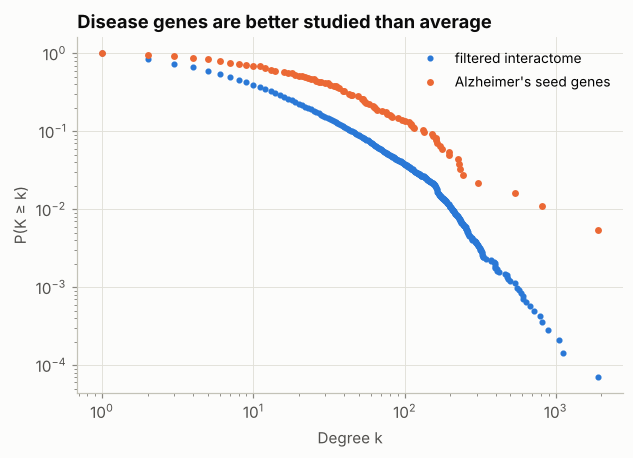

median degree: seed genes 21 vs all proteins 6


In [5]:
def ccdf(values):
    values = np.sort(np.asarray(values))
    unique, first = np.unique(values, return_index=True)
    return unique, 1 - first / len(values)

with plot_style():
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    k, p = ccdf([d for _, d in interactome.degree()])
    ax.loglog(k, p, marker="o", markersize=3, linestyle="none", color=PALETTE[0], label="filtered interactome")
    seeds = map_genes(interactome, data.seed_genes).mapped
    k, p = ccdf([interactome.degree(s) for s in seeds])
    ax.loglog(k, p, marker="o", markersize=3.5, linestyle="none", color=PALETTE[1], label="Alzheimer's seed genes")
    ax.set(xlabel="Degree k", ylabel="P(K ≥ k)")
    ax.set_title("Disease genes are better studied than average")
    ax.legend()
    plt.show()

seed_deg = np.median([interactome.degree(s) for s in seeds])
all_deg = np.median([d for _, d in interactome.degree()])
print(f"median degree: seed genes {seed_deg:.0f} vs all proteins {all_deg:.0f}")

Seed genes have a much higher median degree than an average protein. Disease genes are studied more,
so more of their interactions are known (study bias). This is why the disease-module test in notebook 02
compares the seeds with **degree-matched** random gene sets instead of uniformly random ones.

## 3. Seed coverage

In [6]:
mapping = map_genes(interactome, data.seed_genes)
print(f"{len(mapping.mapped)} of {len(mapping.mapped) + len(mapping.missing)} seed genes are in the interactome "
      f"({mapping.coverage:.0%})")
print("missing:", ", ".join(sorted(symbols[g] for g in mapping.missing)))

183 of 196 seed genes are in the interactome (93%)
missing: ABCA7, CALHM1, CASS4, CYP2D6, CYP46A1, MS4A4A, MS4A6A, NPS, SLC18A3, SLC24A4, SLC30A4, SLC30A6, STH


The missing genes have no interactions linking them to the main component of the filtered interactome. Most
are GWAS loci whose proteins are poorly characterised (MS4A4A, MS4A6A, CASS4, SLC24A4). Network methods
cannot place them.

## 4. Drugs and their targets

In [7]:
targets = data.drug_targets.groupby("drug")["symbol"].apply(lambda s: ", ".join(sorted(s)))
pd.DataFrame({"targets": targets, "n_targets": data.drug_targets.groupby("drug").size()})

,targets,n_targets
drug,,
Donepezil,"ACHE, CYP2C9, CYP2D6, CYP3A4, HRH3, HTR2A, SIG...",7
Galantamine,"ACHE, BCHE, CHRFAM7A, CHRNA1, CHRNA10, CHRNA2,...",21
Memantine,"CYP2A6, CYP2B6, CYP2C19, DRD2, GRIN1, GRIN2A, ...",10
Rivastigmine,"ACHE, BCHE, CYP2D6, CYP3A4",4


The four approved AD drugs are three cholinesterase inhibitors (donepezil, galantamine, rivastigmine)
and the NMDA-receptor antagonist memantine. Their targets are acetylcholinesterase, butyrylcholinesterase, nicotinic
acetylcholine receptors and glutamate receptors, plus the cytochrome P450 enzymes that metabolise the drugs: symptomatic treatments acting on neurotransmission,
not on amyloid or tau. Notebook 02 asks where these targets sit in the disease network.

In addition, 1,689 proteins are bound by at least one DrugBank compound in Hetionet (**druggable**). This flag is
shown as a node border in Cytoscape.

In [8]:
pathway_sizes = pd.Series({k: len(v) for k, v in data.pathways.items()})
go_sizes = pd.Series({k: len(v) for k, v in data.go_processes.items()})
pd.DataFrame({"gene sets": [len(pathway_sizes), len(go_sizes)],
              "median size": [pathway_sizes.median(), go_sizes.median()]},
             index=["pathways", "GO biological processes"])

,gene sets,median size
pathways,1822,23.0
GO biological processes,11381,10.0


These collections are the annotation used in notebook 02 to name the functional clusters.